<a href="https://colab.research.google.com/github/vishwa24816/Option-Pricing-Simulation-/blob/main/Option%20Pricing%20Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
SPOT, DAYS, IV = 25000.0, 7, 0.14
R, Q = 0.065, 0.013
STEP, N_STRIKES = 50, 20
TREE_STEPS, MC_PATHS, SEED = 500, 200_000, 42

# optional live spot:
# import yfinance as yf
# SPOT = float(yf.Ticker("^NSEI").history(period="1d")["Close"].iloc[-1])

T = DAYS / 365.0
ATM = round(SPOT / STEP) * STEP
STRIKES = ATM + STEP * np.arange(-N_STRIKES, N_STRIKES + 1)

In [3]:
def bs_chain(S, K, T, r, q, sigma):
    K = np.asarray(K, dtype=float)
    d1 = (np.log(S/K) + (r - q + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    call = S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    put  = K*np.exp(-r*T)*norm.cdf(-d2) - S*np.exp(-q*T)*norm.cdf(-d1)
    return call, put

In [4]:
def binomial_chain(S, K, T, r, q, sigma, N=500):
    K = np.asarray(K, dtype=float)
    dt = T / N
    u = np.exp(sigma*np.sqrt(dt)); d = 1/u
    p = (np.exp((r - q)*dt) - d) / (u - d)
    disc = np.exp(-r*dt)
    j = np.arange(N + 1)
    ST = (S * u**(N - j) * d**j)[:, None]
    out = []
    for payoff in (np.maximum(ST - K, 0), np.maximum(K - ST, 0)):
        V = payoff
        for _ in range(N):
            V = disc * (p*V[:-1] + (1 - p)*V[1:])
        out.append(V[0])
    return out[0], out[1]

In [5]:
def trinomial_chain(S, K, T, r, q, sigma, N=500):
    K = np.asarray(K, dtype=float)
    dt = T / N
    dx = sigma*np.sqrt(3*dt)
    nu = r - q - 0.5*sigma**2
    a = (sigma**2*dt + nu**2*dt**2) / dx**2
    b = nu*dt / dx
    pu, pd_ = 0.5*(a + b), 0.5*(a - b)
    pm = 1 - pu - pd_
    disc = np.exp(-r*dt)
    j = np.arange(N, -N - 1, -1)
    ST = (S * np.exp(j*dx))[:, None]
    out = []
    for payoff in (np.maximum(ST - K, 0), np.maximum(K - ST, 0)):
        V = payoff
        for _ in range(N):
            V = disc * (pu*V[:-2] + pm*V[1:-1] + pd_*V[2:])
        out.append(V[0])
    return out[0], out[1]

In [6]:
def mc_chain(S, K, T, r, q, sigma, n_paths=200_000, seed=42):
    K = np.asarray(K, dtype=float)
    rng = np.random.default_rng(seed)
    z = rng.standard_normal(n_paths // 2)
    z = np.concatenate([z, -z])                      # antithetic
    ST = S*np.exp((r - q - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)[:, None]
    disc = np.exp(-r*T)
    c = disc*np.maximum(ST - K, 0)
    p = disc*np.maximum(K - ST, 0)
    n = len(z)
    return c.mean(0), p.mean(0), c.std(0, ddof=1)/np.sqrt(n), p.std(0, ddof=1)/np.sqrt(n)

In [7]:
def to_chain(call, put, strikes=STRIKES):
    df = pd.DataFrame({"CE": call, "Strike": strikes, "PE": put})
    df["Straddle"] = df["CE"] + df["PE"]
    return df.set_index("Strike")

In [8]:
bs_c,  bs_p  = bs_chain(SPOT, STRIKES, T, R, Q, IV)
bin_c, bin_p = binomial_chain(SPOT, STRIKES, T, R, Q, IV, TREE_STEPS)
tri_c, tri_p = trinomial_chain(SPOT, STRIKES, T, R, Q, IV, TREE_STEPS)
mc_c, mc_p, mc_ce_se, mc_pe_se = mc_chain(SPOT, STRIKES, T, R, Q, IV, MC_PATHS, SEED)

chains = {
    "Black-Scholes": to_chain(bs_c, bs_p),
    "Binomial":      to_chain(bin_c, bin_p),
    "Trinomial":     to_chain(tri_c, tri_p),
    "Monte Carlo":   to_chain(mc_c, mc_p),
}
chains["Monte Carlo"]["CE_stderr"] = mc_ce_se
chains["Monte Carlo"]["PE_stderr"] = mc_pe_se

for name, df in chains.items():
    print(f"\n=== {name} ===")
    display(df)


=== Black-Scholes ===


,CE,PE,Straddle
Strike,,,
24000,"1,026.29",2.62,"1,028.90"
24050,977.26,3.53,980.78
24100,928.50,4.70,933.20
24150,880.06,6.21,886.27
24200,832.03,8.12,840.15
24250,784.49,10.51,795.00
24300,737.52,13.48,751.01
24350,691.24,17.14,708.37
24400,645.75,21.58,667.33



=== Binomial ===


,CE,PE,Straddle
Strike,,,
24000,"1,026.28",2.62,"1,028.90"
24050,977.25,3.52,980.77
24100,928.48,4.69,933.16
24150,880.04,6.18,886.22
24200,832.03,8.11,840.14
24250,784.50,10.52,795.01
24300,737.53,13.49,751.02
24350,691.23,17.12,708.35
24400,645.69,21.52,667.21



=== Trinomial ===


,CE,PE,Straddle
Strike,,,
24000,"1,026.28",2.62,"1,028.90"
24050,977.26,3.53,980.78
24100,928.50,4.71,933.21
24150,880.05,6.20,886.24
24200,832.04,8.13,840.17
24250,784.50,10.52,795.01
24300,737.51,13.47,750.98
24350,691.26,17.15,708.41
24400,645.74,21.57,667.31



=== Monte Carlo ===


,CE,PE,Straddle,CE_stderr,PE_stderr
Strike,,,,,
24000,"1,026.44",2.73,"1,029.17",1.07,0.06
24050,977.43,3.67,981.10,1.07,0.08
24100,928.69,4.87,933.56,1.06,0.09
24150,880.29,6.40,886.69,1.06,0.10
24200,832.29,8.34,840.63,1.05,0.12
24250,784.79,10.78,795.57,1.04,0.14
24300,737.87,13.79,751.66,1.03,0.16
24350,691.62,17.49,709.11,1.02,0.18
24400,646.17,21.97,668.15,1.00,0.20


In [9]:
cmp = pd.DataFrame(index=STRIKES)
for name in ["Binomial", "Trinomial", "Monte Carlo"]:
    cmp[f"{name} CE diff"] = chains[name]["CE"].values - chains["Black-Scholes"]["CE"].values
    cmp[f"{name} PE diff"] = chains[name]["PE"].values - chains["Black-Scholes"]["PE"].values
cmp.index.name = "Strike"
print("Max abs error vs Black-Scholes:")
display(cmp.abs().max().to_frame("max |diff|"))

theory = SPOT*np.exp(-Q*T) - STRIKES*np.exp(-R*T)     # C - P
parity = pd.DataFrame({n: (df["CE"] - df["PE"]).values - theory for n, df in chains.items()},
                      index=STRIKES)
print("\nParity residual (should be ~0):")
display(parity.abs().max().to_frame("max |residual|"))
display(cmp)

Max abs error vs Black-Scholes:


,max |diff|
Binomial CE diff,0.10
Binomial PE diff,0.10
Trinomial CE diff,0.10
Trinomial PE diff,0.10
Monte Carlo CE diff,0.58
Monte Carlo PE diff,0.55



Parity residual (should be ~0):


,max |residual|
Black-Scholes,0.00
Binomial,0.00
Trinomial,0.00
Monte Carlo,0.03


,Binomial CE diff,Binomial PE diff,Trinomial CE diff,Trinomial PE diff,Monte Carlo CE diff,Monte Carlo PE diff
Strike,,,,,,
24000,-0.00,-0.00,-0.00,-0.00,0.15,0.12
24050,-0.01,-0.01,0.00,0.00,0.17,0.14
24100,-0.02,-0.02,0.01,0.01,0.20,0.16
24150,-0.03,-0.03,-0.01,-0.01,0.23,0.19
24200,-0.01,-0.01,0.01,0.01,0.26,0.22
24250,0.01,0.01,0.00,0.00,0.30,0.27
24300,0.01,0.01,-0.01,-0.01,0.34,0.31
24350,-0.01,-0.01,0.02,0.02,0.39,0.35
24400,-0.06,-0.06,-0.01,-0.01,0.43,0.39


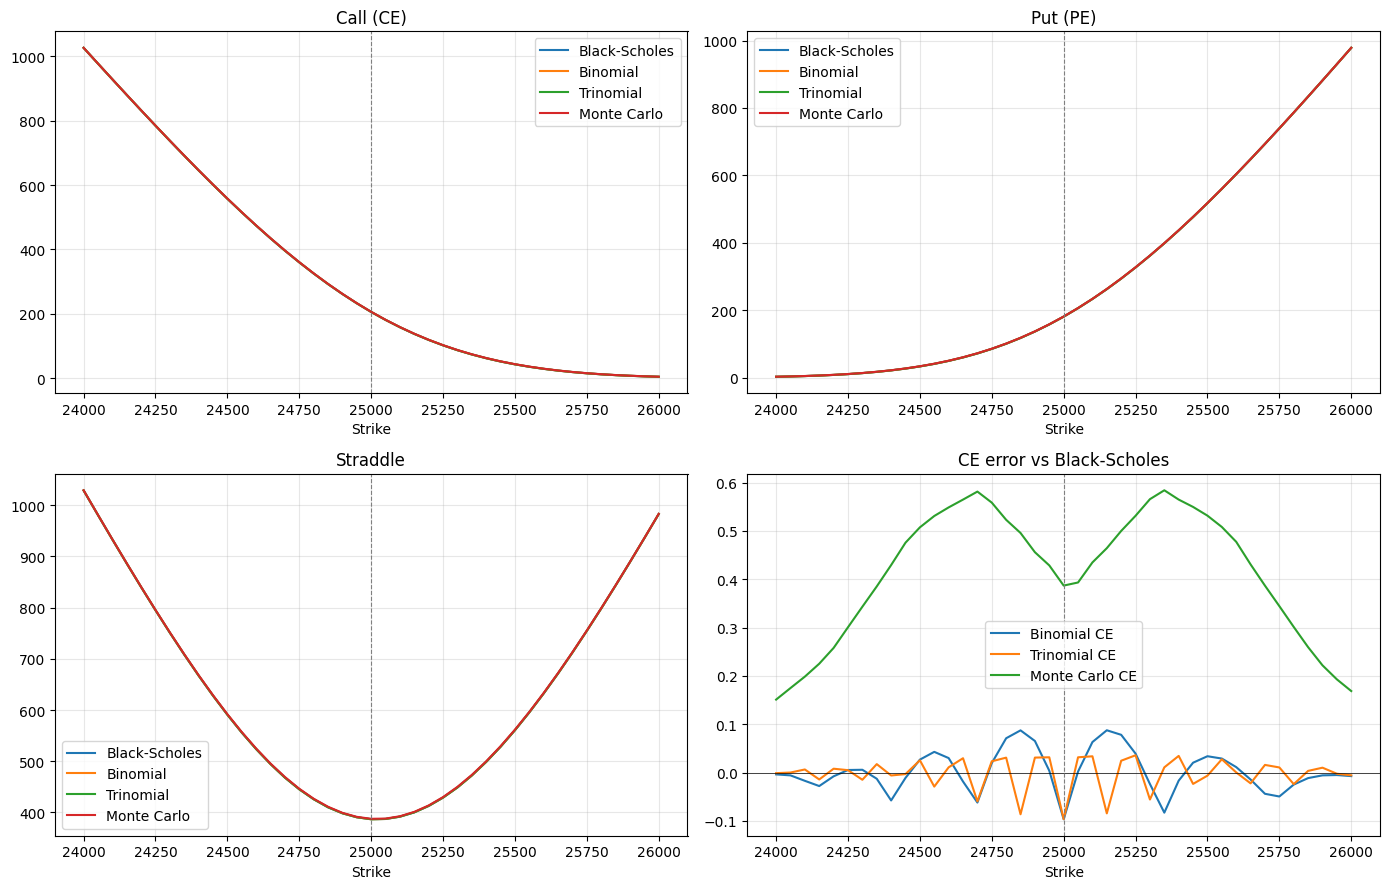

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for name, df in chains.items():
    ax[0, 0].plot(df.index, df["CE"], label=name)
    ax[0, 1].plot(df.index, df["PE"], label=name)
    ax[1, 0].plot(df.index, df["Straddle"], label=name)
ax[0, 0].set_title("Call (CE)"); ax[0, 1].set_title("Put (PE)"); ax[1, 0].set_title("Straddle")
for name in ["Binomial", "Trinomial", "Monte Carlo"]:
    ax[1, 1].plot(STRIKES, chains[name]["CE"].values - chains["Black-Scholes"]["CE"].values, label=f"{name} CE")
ax[1, 1].axhline(0, color="k", lw=0.5); ax[1, 1].set_title("CE error vs Black-Scholes")
for a in ax.ravel():
    a.axvline(SPOT, color="grey", ls="--", lw=0.8); a.set_xlabel("Strike"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()